# Altair optical pooled screen: starter notebook

This notebook downloads the guide-level phase profiles and up to 100 cells per guide, scores how well each knockout separates from the non-targeting controls with mantispy, draws a map of the knockouts, and joins Biohub's CROP-seq embedding by guide sequence. It runs on a laptop in a few minutes and needs about 4 GB of memory.

In [1]:
import os
import time
from pathlib import Path

import anndata as ad
import mantispy as mt
import numpy as np
import pandas as pd
import scanpy as sc

T0 = time.time()
DATA = Path(os.environ.get("ALTAIR_DATA", "data"))
URL = "https://exampledata.scverse.org/sbi2-cytodata/ops"
FILES = ["phase_guide.h5ad", "phase_guide_x_screen.h5ad", "phase_cells_n100.h5ad", "screen_map.csv", "unexpressed_genes.csv"]
DATA.mkdir(exist_ok=True)
for f in FILES:
    if not (DATA / f).exists():
        os.system(f"curl -sSf -o {DATA / f} {URL}/{f}")
{f: f"{(DATA / f).stat().st_size / 1e9:.2f} GB" for f in FILES}

{'phase_guide.h5ad': '0.05 GB',
 'phase_guide_x_screen.h5ad': '3.13 GB',
 'phase_cells_n100.h5ad': '6.33 GB',
 'screen_map.csv': '0.00 GB',
 'unexpressed_genes.csv': '0.00 GB'}

## Guide profiles

`phase_guide.h5ad` holds one robust z-scored phase profile per guide, the median of the guide's per-screen medians. We keep the features that mantispy's feature selection kept, and we clip the z-scores at 50 because a few features have a very small spread among the control cells.

In [2]:
guides = ad.read_h5ad(DATA / "phase_guide.h5ad")
guides = guides[:, guides.var["selected"].values].copy()
guides.X = np.clip(np.nan_to_num(guides.X), -50, 50)
print(guides)
guides.obs[["guide", "target_gene", "n_cells", "n_screens"]].head()

AnnData object with n_obs × n_vars = 4211 × 337
    obs: 'Metadata_sgRNA', 'Metadata_CellCount', 'channel_rank', 'gene', 'modality', 'op_channel', 'op_match', 'sgRNA', 'viz_channel', 'target_gene', 'guide', 'Metadata_Gene', 'Metadata_ObjectType', 'Metadata_Perturbation', 'Metadata_Perturbation_Type', 'Metadata_CellLine', 'Metadata_Row', 'Metadata_Control_Type', 'Metadata_Control', 'qc_is_border', 'qc_area_outlier', 'qc_pass', 'qc_high_nan', 'qc_tile_duplicate', 'norm_reference', 'n_screens', 'n_cells'
    var: 'feature_name', 'organelle', 'metric', 'category', 'aggregation', 'unit', 'op_units_corrected', 'source', 'zscored_per_batch', 'modality', 'degenerate_scale', 'n_extreme', 'qc_all_nan', 'qc_high_nan', 'qc_extreme', 'qc_degenerate', 'selected'
    uns: 'cytodata', 'mantispy'
    layers: None (.X)


,guide,target_gene,n_cells,n_screens
0,AAAACAACATCGAAGATGTG,GAK,16055.0,87
1,AAAACACATCAGTATAACAT,RHOA,13697.0,87
2,AAAACAGGACGATGTGCGGC,NTC,31978.0,87
3,AAAACATCGACCGAAAGCGT,NTC,17623.0,87
4,AAAACCATTTACCTCTGCAA,RPL15,5154.0,87


## Which knockouts have a phenotype

`mt.tl.map` with `mode="activity"` asks whether the four guides of a gene retrieve each other better than they retrieve the control guides, and it reports a mean average precision (`score`) with a permutation q-value per gene. All guide profiles are pooled across screens, so we put them in one batch.

The choice of control matters. Every targeting guide cuts the DNA and the non-targeting guides don't, so against `NTC` almost every knockout separates, including knockouts of genes that A549 cells don't express. A fairer control is the knockouts of the 74 single-copy genes that A549 doesn't express (`unexpressed_genes.csv`), because those guides cut the DNA without removing a gene the cells use. We run both.

In [3]:
unexpressed = pd.read_csv(DATA / "unexpressed_genes.csv")
cutting_control = set(unexpressed.query("not multicopy")["gene"])
guides.obs["Metadata_Plate"] = "all"
guides.obs["cutting_control"] = guides.obs["target_gene"].isin(cutting_control).values
t = time.time()
mt.tl.map(guides, mode="activity", label="Metadata_Gene", batch="Metadata_Plate", reference="negcon", null_size=20_000, key_added="map_ntc")
mt.tl.map(guides, mode="activity", label="Metadata_Gene", batch="Metadata_Plate", reference="cutting_control", null_size=20_000, key_added="map_cut")
vs_ntc, activity = guides.uns["mantispy"]["map_ntc"], guides.uns["mantispy"]["map_cut"]
activity = activity[~activity["Metadata_Gene"].isin(cutting_control | {"NTC"})]
print(f"{time.time() - t:.0f} s")
print(f"against NTC: {vs_ntc['is_significant'].mean():.1%} of {len(vs_ntc)} knockouts separate (q < 0.05)")
print(f"against the cutting control: {activity['is_significant'].mean():.1%} of {len(activity)} knockouts separate (q < 0.05)")
multicopy = set(unexpressed.query("multicopy")["gene"])
rank = vs_ntc.sort_values("score", ascending=False).reset_index(drop=True)
print("rank against NTC of unexpressed multicopy genes (their guides cut many copies):", {g: int(i) + 1 for i, g in rank["Metadata_Gene"].items() if g in multicopy})
activity.sort_values("score", ascending=False).head(10)

26 s
against NTC: 99.9% of 1000 knockouts separate (q < 0.05)
against the cutting control: 75.1% of 926 knockouts separate (q < 0.05)
rank against NTC of unexpressed multicopy genes (their guides cut many copies): {'SPRR2A': 29, 'SPRR2B': 30, 'TBC1D3G': 34, 'GGTLC2': 127, 'FOXD4L5': 128, 'GOLGA6D': 142, 'GOLGA6L1': 143, 'GOLGA8K': 144, 'PRAMEF6': 172, 'PPIAL4D': 222, 'KRTAP2-4': 242, 'TRIM43': 244, 'USP17L5': 259, 'KRTAP2-3': 261, 'KRTAP4-2': 349, 'LCE3A': 380, 'PLGLB2': 501, 'SPATA31A3': 605, 'FOXD4L1': 754, 'SPATA31A5': 894, 'USP17L12': 944}


,Metadata_Gene,score,mean_normalized_average_precision,pvalue,qvalue,below_p,is_significant
26,AP2M1,1.0,1.0,0.00005,0.000188,True,True
924,ZNRD1,1.0,1.0,0.00005,0.000188,True,True
879,URB2,1.0,1.0,0.00005,0.000188,True,True
873,UBR4,1.0,1.0,0.00005,0.000188,True,True
331,GRPEL1,1.0,1.0,0.00005,0.000188,True,True
334,GTF2B,1.0,1.0,0.00005,0.000188,True,True
448,MCM7,1.0,1.0,0.00005,0.000188,True,True
451,MDN1,1.0,1.0,0.00005,0.000188,True,True
358,HNRNPH1,1.0,1.0,0.00005,0.000188,True,True
349,HECTD1,1.0,1.0,0.00005,0.000188,True,True


## A map of the knockouts

A UMAP of the guide profiles, with the non-targeting guides in grey. Genes in the same complex tend to sit together.

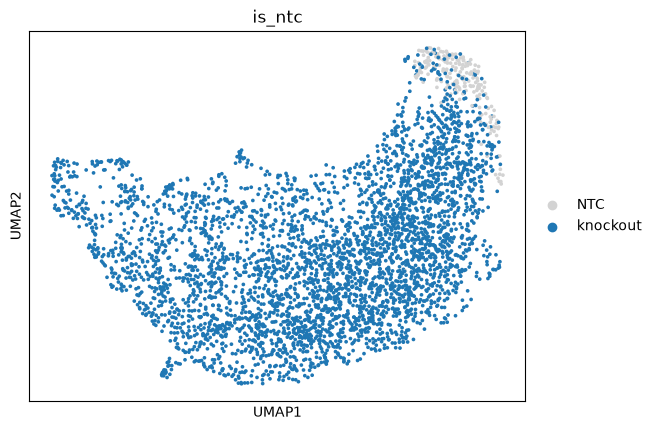

In [4]:
sc.pp.pca(guides, n_comps=50)
sc.pp.neighbors(guides, n_neighbors=15, transformer="sklearn")
sc.tl.umap(guides, random_state=0)
guides.obs["is_ntc"] = (guides.obs["target_gene"] == "NTC").map({True: "NTC", False: "knockout"})
sc.pl.umap(guides, color="is_ntc", palette={"NTC": "lightgrey", "knockout": "tab:blue"})

## Single cells

`phase_cells_n100.h5ad` holds up to 100 cells per guide. Reading it in backed mode and loading only the selected features and the cells that pass QC keeps the memory use small.

In [5]:
import gc

import h5py
from anndata.io import read_elem

# Read obs, var and the selected columns of X straight from the file. A backed AnnData would load
# layers["raw"] (about 5.5 GB) into memory even though we never use it.
with h5py.File(DATA / "phase_cells_n100.h5ad", "r") as f:
    obs, var = read_elem(f["obs"]), read_elem(f["var"])
    keep_cells = obs["qc_pass"].values
    keep_features = np.flatnonzero(var["selected"].values)
    blocks = [f["X"][lo : lo + 10_000][keep_cells[lo : lo + 10_000]][:, keep_features] for lo in range(0, len(obs), 10_000)]
cells = ad.AnnData(np.clip(np.nan_to_num(np.vstack(blocks)), -50, 50), obs=obs[keep_cells], var=var.iloc[keep_features])
del blocks
gc.collect()
print(cells.shape, f"{cells.X.nbytes / 1e9:.2f} GB")
cells.obs.groupby("target_gene", observed=True).size().describe()

(391748, 337) 0.53 GB


count     1001.000000
mean       391.356643
std        614.352226
min        326.000000
25%        369.000000
50%        373.000000
75%        376.000000
max      19808.000000
dtype: float64

## CROP-seq of the same library

Biohub's Zenodo record has a CROP-seq embedding for each guide. Its `sgRNA` column is the guide sequence, so it joins to our `guide` column. The CROP-seq cells are not the imaged cells, so the two modalities only line up at the guide level.

In [6]:
import zipfile

zpath = DATA / "altair_v2.zip"
if not zpath.exists():
    os.system(f"curl -sSfL -o {zpath} https://zenodo.org/api/records/21970895/files/altair_v2.zip/content")
with zipfile.ZipFile(zpath) as z:
    z.extract("figures/figure_5/cropseq_svaeplus.h5ad", DATA)
rna = ad.read_h5ad(DATA / "figures/figure_5/cropseq_svaeplus.h5ad")
rna_emb = pd.DataFrame(rna.obsm["emb_guide"], index=rna.obs["sgRNA"].values)
shared = guides.obs["guide"].astype(str).isin(rna_emb.index)
print(f"{shared.sum()} of {guides.n_obs} guides have a CROP-seq embedding")
joint = guides[shared.values].copy()
joint.obsm["X_rna"] = rna_emb.loc[joint.obs["guide"].astype(str)].values
joint

4206 of 4211 guides have a CROP-seq embedding


AnnData object with n_obs × n_vars = 4206 × 337
    obs: 'Metadata_sgRNA', 'Metadata_CellCount', 'channel_rank', 'gene', 'modality', 'op_channel', 'op_match', 'sgRNA', 'viz_channel', 'target_gene', 'guide', 'Metadata_Gene', 'Metadata_ObjectType', 'Metadata_Perturbation', 'Metadata_Perturbation_Type', 'Metadata_CellLine', 'Metadata_Row', 'Metadata_Control_Type', 'Metadata_Control', 'qc_is_border', 'qc_area_outlier', 'qc_pass', 'qc_high_nan', 'qc_tile_duplicate', 'norm_reference', 'n_screens', 'n_cells', 'Metadata_Plate', 'cutting_control', 'map_ntc', 'map_ntc_qvalue', 'map_cut', 'map_cut_qvalue', 'is_ntc'
    var: 'feature_name', 'organelle', 'metric', 'category', 'aggregation', 'unit', 'op_units_corrected', 'source', 'zscored_per_batch', 'modality', 'degenerate_scale', 'n_extreme', 'qc_all_nan', 'qc_high_nan', 'qc_extreme', 'qc_degenerate', 'selected'
    uns: 'cytodata', 'mantispy', 'pca', 'neighbors', 'umap', 'is_ntc_colors'
    obsm: 'X_pca', 'X_umap', 'X_rna'
    varm: 'PCs'
    ob

## How much of the morphology neighbourhood is also an RNA neighbourhood

For each knockout guide we take its 10 nearest guides by phase profile and its 10 nearest guides by CROP-seq embedding (cosine distance), and we count how many of the 10 are shared. We compare the mean overlap with the overlap after shuffling which RNA embedding belongs to which guide.

In [7]:
from sklearn.neighbors import NearestNeighbors

ko = joint[joint.obs["target_gene"] != "NTC"]
k = 10


def knn(x):
    return NearestNeighbors(n_neighbors=k + 1, metric="cosine").fit(x).kneighbors(x, return_distance=False)[:, 1:]


def overlap(a, b):
    return np.mean([len(set(x) & set(y)) / k for x, y in zip(a, b)])


phase_nn = knn(ko.X)
rna = ko.obsm["X_rna"]
observed = overlap(phase_nn, knn(rna))
rng = np.random.default_rng(0)
shuffled = [overlap(phase_nn, knn(rna[rng.permutation(len(rna))])) for _ in range(5)]
print(f"{observed:.1%} of a guide's 10 phase neighbours are also among its 10 RNA neighbours, against {np.mean(shuffled):.1%} after shuffling")

13.8% of a guide's 10 phase neighbours are also among its 10 RNA neighbours, against 0.2% after shuffling


## What a fluorescent marker adds

The marker files have the same tiers for each of the 59 markers. Phase alone already separates most knockouts, so a marker adds a few, specific ones. Here we score the COP-II coat marker SEC23A, which labels where cargo leaves the endoplasmic reticulum, against the same cutting control, and we list the knockouts that separate with SEC23A but not with phase. They should be genes of the secretory pathway.

In [8]:
mpath = DATA / "markers_guide.zip"
if not mpath.exists():
    os.system(f"curl -sSf -o {mpath} {URL}/markers_guide.zip")
with zipfile.ZipFile(mpath) as z:
    z.extract("er_golgi_cop-ii_sec23a_guide.h5ad", DATA)
marker = ad.read_h5ad(DATA / "er_golgi_cop-ii_sec23a_guide.h5ad")
marker = marker[:, marker.var["selected"].values].copy()
marker.X = np.clip(np.nan_to_num(marker.X), -50, 50)
marker.obs["Metadata_Plate"] = "all"
marker.obs["cutting_control"] = marker.obs["target_gene"].isin(cutting_control).values
mt.tl.map(marker, mode="activity", label="Metadata_Gene", batch="Metadata_Plate", reference="cutting_control", null_size=20_000)
marker_map = marker.uns["mantispy"]["map"]
marker_hits = set(marker_map[~marker_map["Metadata_Gene"].isin(cutting_control | {"NTC"})].query("is_significant")["Metadata_Gene"])
phase_hits = set(activity.query("is_significant")["Metadata_Gene"])
only_marker = sorted(marker_hits - phase_hits)
print(f"{len(marker_hits)} knockouts separate with SEC23A, {len(phase_hits)} with phase, {len(only_marker)} only with SEC23A")
only_marker[:30]

113 knockouts separate with SEC23A, 695 with phase, 3 only with SEC23A


['SEC23B', 'SEL1L', 'TMED10']

In [9]:
print(f"total runtime {time.time() - T0:.0f} s")

total runtime 119 s
